# Exploratory Data Analysis

### Datasets

| Dataset | Rows | Task | Output variable |
|---|---|---|---|
| Adult Income (UCI 2) | ~48,800 | Binary classification | `income`: 1 if > \$50K, else 0 |
| AI4I 2020 Predictive Maintenance (UCI 601) | 10,000 | Binary classification | `Machine failure`: 1 if the machine failed |

### Boilerplate Code

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

from src.data import load_raw, load_dataset, feature_types, AI4I_FAILURE_MODES

pd.set_option("display.max_columns", 50)

---
# Part 1: Adult Income

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `workclass` | Employer type (private, government, self-employed, ...) |
| `fnlwgt` | Census sampling weight (how many people this row represents) |
| `education-num` | Highest education level as a number (1–16) |
| `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country` | Categorical attributes |
| `capital-gain`, `capital-loss` | Investment income / losses (\$) |
| `hours-per-week` | Hours worked per week |
| **`income`** | **Output variable:** 1 if income > \$50K, else 0 |

`education` is dropped when loading because it is a duplicate of `education-num` (same information, text vs. number).

In [2]:
X_adult, y_adult = load_dataset("adult")
df_adult = X_adult.assign(income=y_adult)   # features and output together

num_adult, cat_adult = feature_types(X_adult)
print("Numeric features:    ", num_adult)
print("Categorical features:", cat_adult)
df_adult.head()

Numeric features:     ['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features: ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


## Look for missing or duplicate values:

In [3]:
missing = pd.DataFrame({
    "n_missing": X_adult.isna().sum(),
    "% missing": (100 * X_adult.isna().mean()).round(2),
})
print(missing[missing.n_missing > 0])

# Rows with at least one missing value
print(f"\nRows with any missing value: {X_adult.isna().any(axis=1).sum():,} of {len(X_adult):,}")

# Exact duplicate rows
print(f"Duplicate rows: {df_adult.duplicated().sum():,}")

                n_missing  % missing
workclass            2393       5.77
occupation           2403       5.80
native_country        853       2.06

Rows with any missing value: 3,210 of 41,439
Duplicate rows: 0


**What we found:**
- Three columns have missing values: `workclass` (5.8%), `occupation` (5.8%) and `native_country` (2.1%).
- 3,210 rows (7.7%) have at least one missing value.
- There are no duplicate rows.

## Does it matter which rows specifically are missing?

Check why values are missing before we handle them. If rows with missing values have a different >50K rate, the missingness itself tells you something about income. XGBoost can learn from that pattern, but filling in the gaps with the median or the most common value hides it.

In [4]:
# Compare the >50K rate for rows where each column is missing vs. present
for col in X_adult.columns[X_adult.isna().any()]:
    is_missing = X_adult[col].isna()
    print(f"{col:>15}: >50K rate when missing = {y_adult[is_missing].mean():.3f}, "
          f"when present = {y_adult[~is_missing].mean():.3f}")

      workclass: >50K rate when missing = 0.105, when present = 0.248
     occupation: >50K rate when missing = 0.104, when present = 0.248
 native_country: >50K rate when missing = 0.256, when present = 0.239


**What we found:**
- When `workclass` or `occupation` is missing, only **10.5%** earn >50K, vs. **24.8%** when present.
  Less than half the rate, so these values are not missing at random. Most likely they're the
  same people either not working, or who simply skipped the job questions.
- `native_country` missing vs. present is 25.6% vs. 23.9%. About the same, so this one appears close to random.

**Conclusion:** The missing values carry information about income, so this is where XGBoost's built-in handling should beat simple imputation. To keep the comparison fair, the other models should get "was missing" indicator columns.

## How many people earn more than $50k, and how many don't?

              count  proportion
income > 50K                   
0             31519       0.761
1              9920       0.239


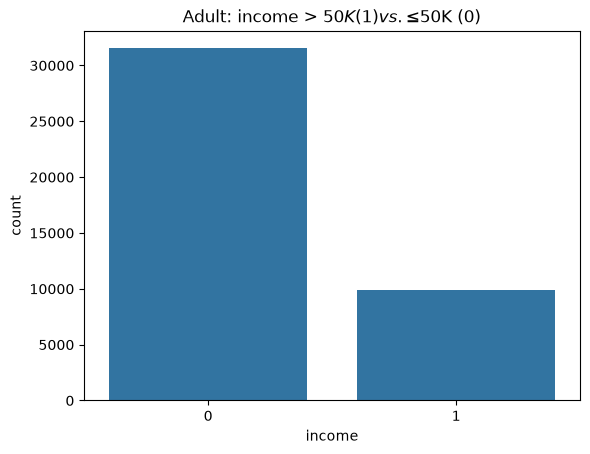

In [5]:
counts = y_adult.value_counts().sort_index()
print(pd.DataFrame({"count": counts, "proportion": (counts / counts.sum()).round(3)},
                   index=pd.Index([0, 1], name="income > 50K")))

sns.countplot(x=y_adult)
plt.title("Adult: income > $50K (1) vs. ≤ $50K (0)")
plt.show()

**What we found:**
- 76.1% earn ≤ \$50K and 23.9% earn > \$50K, which is about **3 to 1**.
- A model that always guesses "≤ \$50K" already gets 76% accuracy without learning anything so accuracy alone isn't enough when measuring performance. We will also need to report F1 and PR-AUC, and split the data with stratification.

## Numerical Feature Behaviors

### Histograms

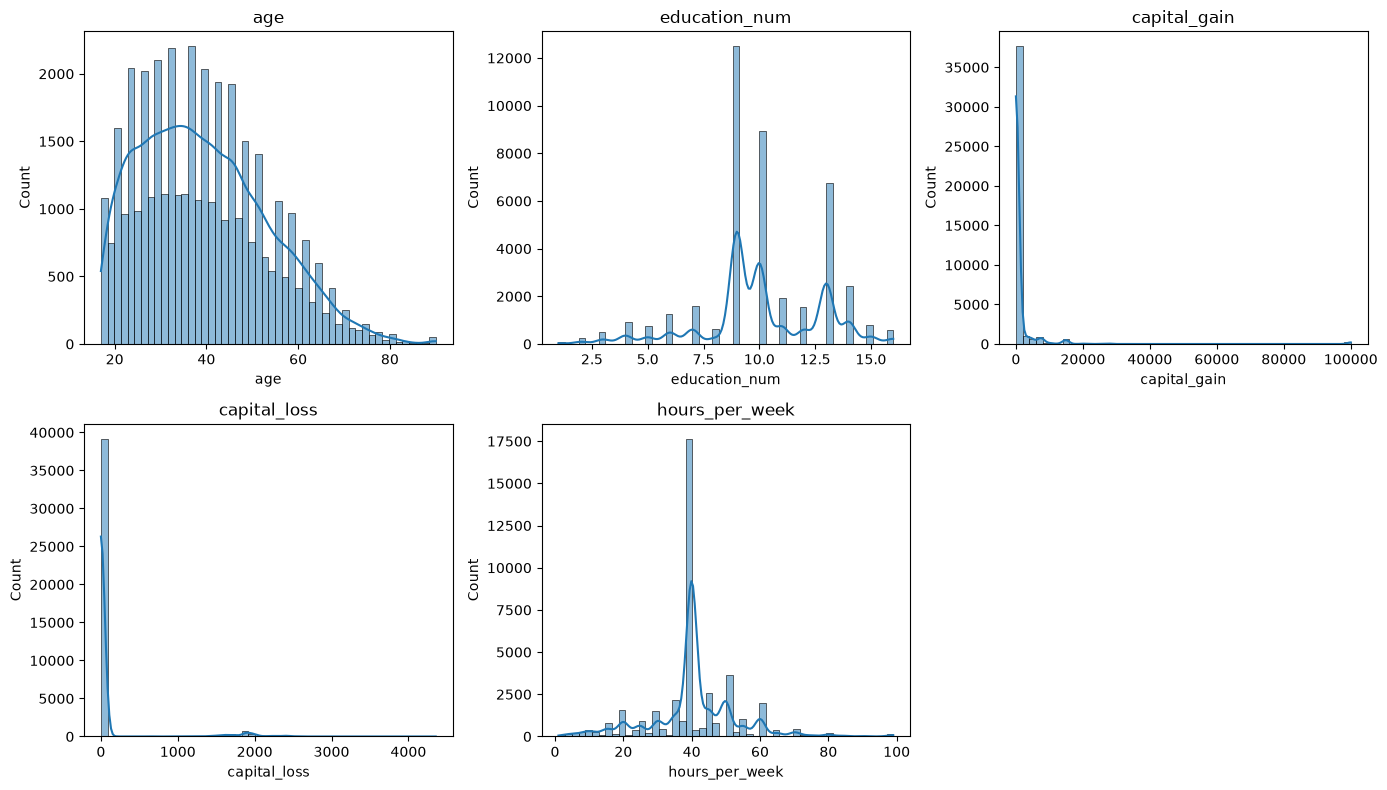

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.ravel(), num_adult):
    sns.histplot(df_adult[feature], bins=50, kde=True, ax=ax)
    ax.set_title(feature)
for ax in axes.ravel()[len(num_adult):]:
    ax.axis("off")   # hide unused panels
plt.tight_layout()
plt.show()

### Summary Stats for the Numerical Features

In [7]:
stats = df_adult[num_adult].agg(["mean", "median", "std", "min", "max"]).T
stats["mean - median"] = stats["mean"] - stats["median"]
stats["pearson skew"] = 3 * stats["mean - median"] / stats["std"]
stats["sample skewness"] = df_adult[num_adult].apply(skew)

# How far the min and max sit from the mean, in std units (similar distances -> symmetric)
stats["(mean - min)/std"] = (stats["mean"] - stats["min"]) / stats["std"]
stats["(max - mean)/std"] = (stats["max"] - stats["mean"]) / stats["std"]
print(stats.round(3))

                    mean  median       std   min      max  mean - median  \
age               39.433    38.0    13.864  17.0     90.0          1.433   
education_num     10.086    10.0     2.674   1.0     16.0          0.086   
capital_gain    1256.560     0.0  8026.980   0.0  99999.0       1256.560   
capital_loss     102.339     0.0   434.075   0.0   4356.0        102.339   
hours_per_week    40.582    40.0    12.983   1.0     99.0          0.582   

                pearson skew  sample skewness  (mean - min)/std  \
age                    0.310            0.539             1.618   
education_num          0.096           -0.361             3.398   
capital_gain           0.470           11.014             0.157   
capital_loss           0.707            4.176             0.236   
hours_per_week         0.134            0.264             3.049   

                (max - mean)/std  
age                        3.647  
education_num              2.212  
capital_gain              12.301  


**What we found:**

| Feature | Skew | Shape |
|---|---|---|
| `age` | 0.54 | Slightly right-skewed with mean 39.4 > median 38, showing more young workers than old |
| `education_num` | −0.36 | Roughly symmetric, with peaks at common levels (HS grad = 9, bachelor's = 13) |
| `capital_gain` | **11.0** | Extremely right-skewed as median is 0 and max is 12.3 std above the mean |
| `capital_loss` | **4.2** | Very right-skewed with median 0, showing a few large values |
| `hours_per_week` | 0.26 | Roughly symmetric, but tightly packed around 40 (full-time) |

### Are any features capped?

In [21]:
for col in num_adult:
    max_val = df_adult[col].max()
    n_at_max = (df_adult[col] == max_val).sum()
    print(f"{col:>15}: max = {max_val}, rows at max = {n_at_max} ({100 * n_at_max / len(df_adult):.2f}%)")

            age: max = 90, rows at max = 53 (0.13%)
  education_num: max = 16, rows at max = 571 (1.38%)
   capital_gain: max = 99999, rows at max = 241 (0.58%)
   capital_loss: max = 4356, rows at max = 3 (0.01%)
 hours_per_week: max = 99, rows at max = 137 (0.33%)


**What we found:**
- `capital_gain` is capped at 99,999, with 241 rows at that value.
- `hours_per_week` is likely capped at 99 (137 rows), and `age` may be capped at 90 (53 rows).
- `education_num` and `capital_loss` are not capped. 16 is the highest education level, and only 3 rows reach the max for capital loss.
- Capping pulls the mean down, and models cannot learn anything above the cap.

### What are the differences for >50k and ≤50K?

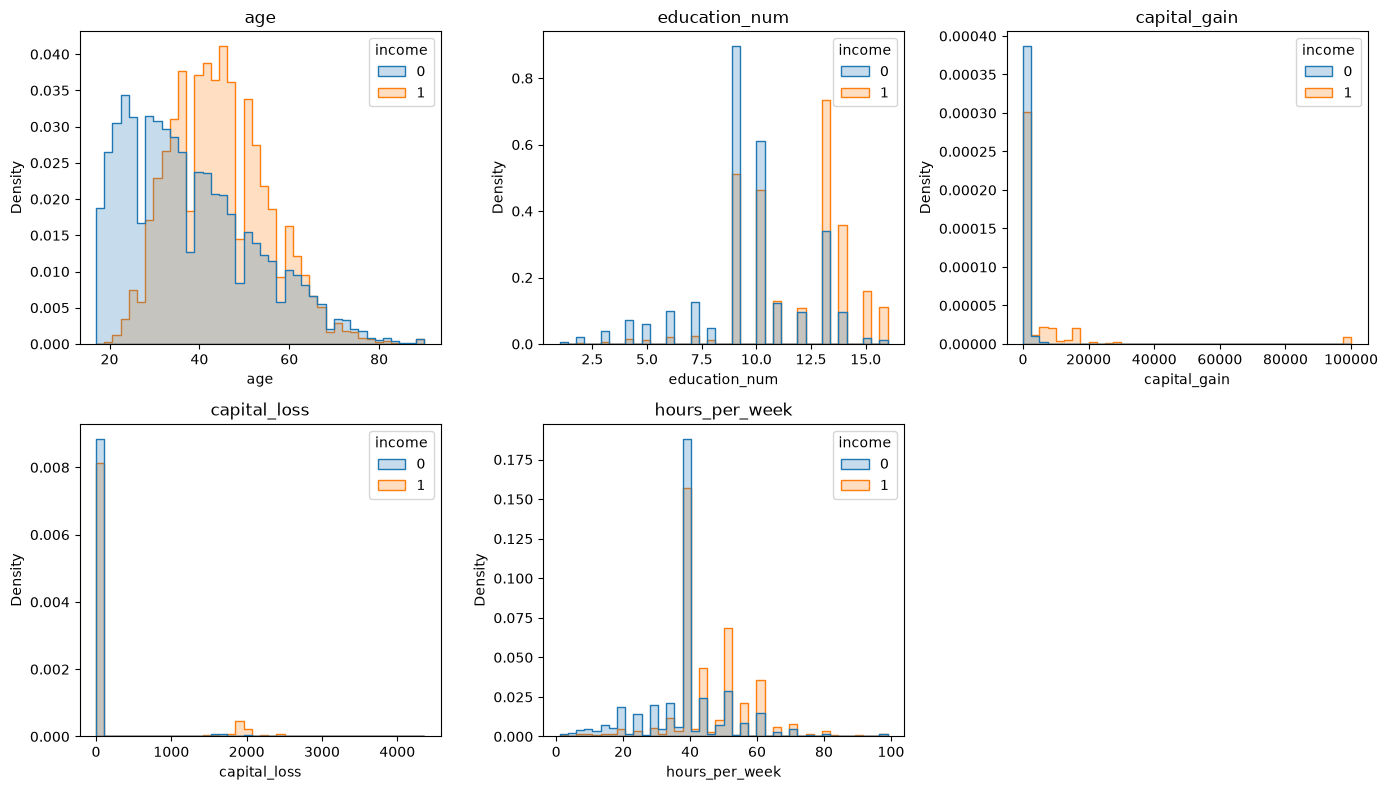

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.ravel(), num_adult):
    sns.histplot(data=df_adult, x=feature, hue="income", bins=40,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(feature)
for ax in axes.ravel()[len(num_adult):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we found:**
- `age`: people earning >50K are mostly 35–55, while people earning ≤50K skew younger, with many in their 20s.
- `education_num`: >50K is concentrated at 13 (bachelor's) and above, while ≤50K is mostly at 9–10 (high school or some college). This is the clearest difference.
- `hours_per_week`: both groups peak at 40, but >50K is more common at 45–60 hours and ≤50K is more common below 40 (part-time).
- `capital_gain` and `capital_loss`: almost everyone is at 0, but nonzero values show up more for >50K, and the largest gains appear only for >50K.
- Overall, higher income goes with being older, more educated, and working longer hours.

### Are there outliers? 

In [8]:
# Q1, Q2, Q3, IQR and the 1.5 x IQR bounds for each numeric attribute
Q1 = df_adult[num_adult].quantile(0.25)
Q2 = df_adult[num_adult].quantile(0.50)
Q3 = df_adult[num_adult].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

is_outlier = (df_adult[num_adult] < lower) | (df_adult[num_adult] > upper)

iqr_table = pd.DataFrame({"Q1": Q1, "Q2": Q2, "Q3": Q3, "IQR": IQR,
                          "lower bound": lower, "upper bound": upper,
                          "n outliers": is_outlier.sum(),
                          "% outliers": (100 * is_outlier.mean()).round(2)})
print(iqr_table.round(3))

                  Q1    Q2    Q3   IQR  lower bound  upper bound  n outliers  \
age             28.0  38.0  49.0  21.0         -3.5         80.5         146   
education_num    9.0  10.0  13.0   4.0          3.0         19.0         322   
capital_gain     0.0   0.0   0.0   0.0          0.0          0.0        3996   
capital_loss     0.0   0.0   0.0   0.0          0.0          0.0        2265   
hours_per_week  38.0  40.0  45.0   7.0         27.5         55.5        9201   

                % outliers  
age                   0.35  
education_num         0.78  
capital_gain          9.64  
capital_loss          5.47  
hours_per_week       22.20  


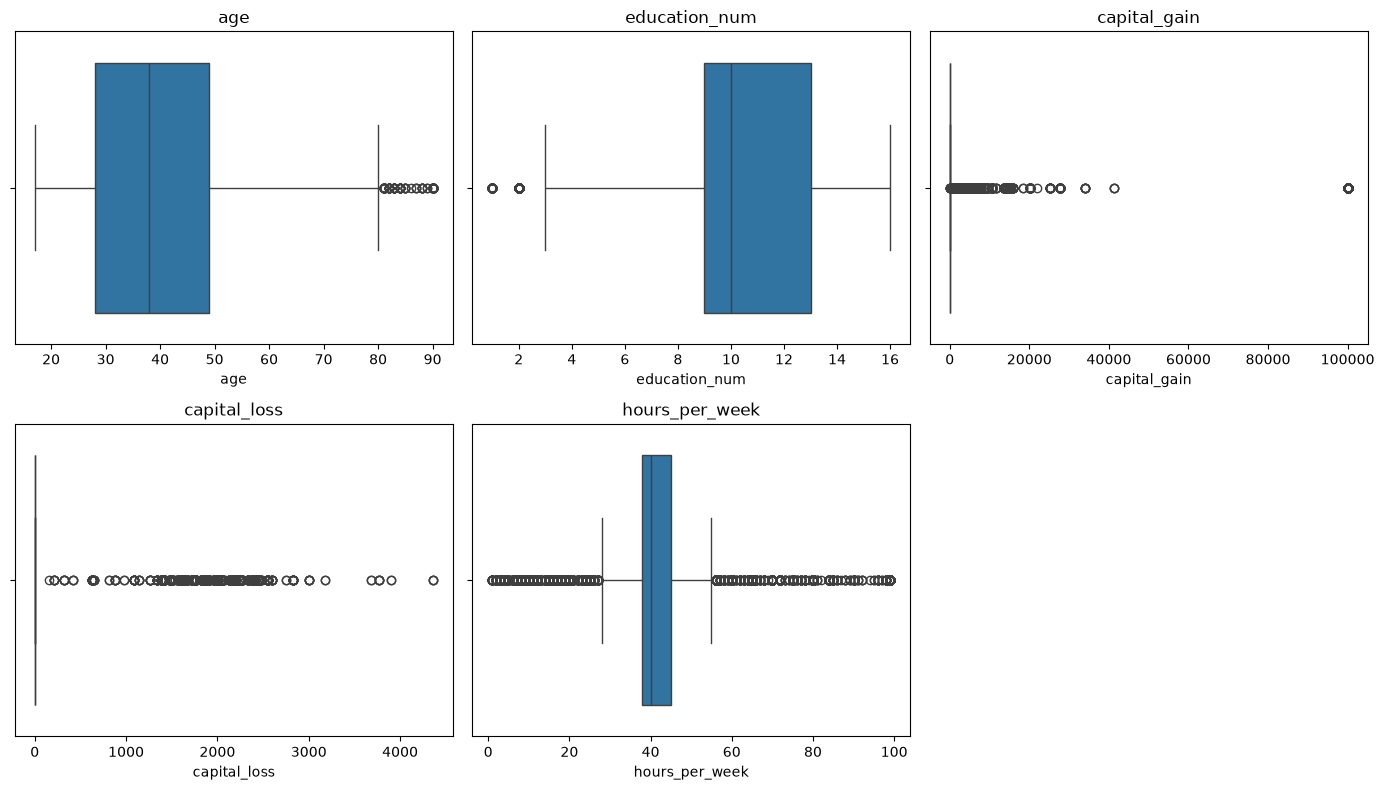

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.ravel(), num_adult):
    sns.boxplot(x=df_adult[feature], ax=ax)
    ax.set_title(feature)
for ax in axes.ravel()[len(num_adult):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
# Rows that are an outlier in at least one attribute
any_outlier = is_outlier.any(axis=1)
print(f"Rows that are an outlier in at least one attribute: {any_outlier.sum():,} "
      f"({100 * any_outlier.mean():.2f}%)")

# Recompute mean and median without those rows
compare = pd.DataFrame({
    "mean (all)": df_adult[num_adult].mean(),
    "mean (no outliers)": df_adult.loc[~any_outlier, num_adult].mean(),
    "median (all)": df_adult[num_adult].median(),
    "median (no outliers)": df_adult.loc[~any_outlier, num_adult].median(),
})
print(compare.round(3))

# Are outlier rows more likely to be >50K? If so, they are signal, not bad data.
print(f"\n>50K rate in outlier rows: {y_adult[any_outlier].mean():.3f}, "
      f"in other rows: {y_adult[~any_outlier].mean():.3f}")

Rows that are an outlier in at least one attribute: 14,510 (35.02%)
                mean (all)  mean (no outliers)  median (all)  \
age                 39.433              38.607          38.0   
education_num       10.086              10.011          10.0   
capital_gain      1256.560               0.000           0.0   
capital_loss       102.339               0.000           0.0   
hours_per_week      40.582              41.161          40.0   

                median (no outliers)  
age                             37.0  
education_num                   10.0  
capital_gain                     0.0  
capital_loss                     0.0  
hours_per_week                  40.0  

>50K rate in outlier rows: 0.334, in other rows: 0.188


**What we found:**
- The rule flags **35% of all rows**, which shows this far too many to mean "bad data".
- It breaks down for `capital_gain` and `capital_loss`: Q1 = Q3 = 0, so IQR = 0 and every nonzero
  value counts as an outlier (9.6% and 5.5% of rows).
- `hours_per_week` has 22% outliers only because the middle half is so narrow (38–45 hours) so anyone working part-time or long hours/overtime gets flagged.
- Outlier rows earn >50K at 33.4%, vs. 18.8% for other rows showing what may be outliers may actually carry some information.

**Conclusion:** Based on these results, we decide to keep the outliers as the data shows that these values do not indicate bad data, yet real circumstances that should be accounted for.

### Do transformations fix the observed skew?

              skew (raw)  skew (z-score)  skew (log1p)
capital_gain      11.014          11.014         2.812
capital_loss       4.176           4.176         3.925


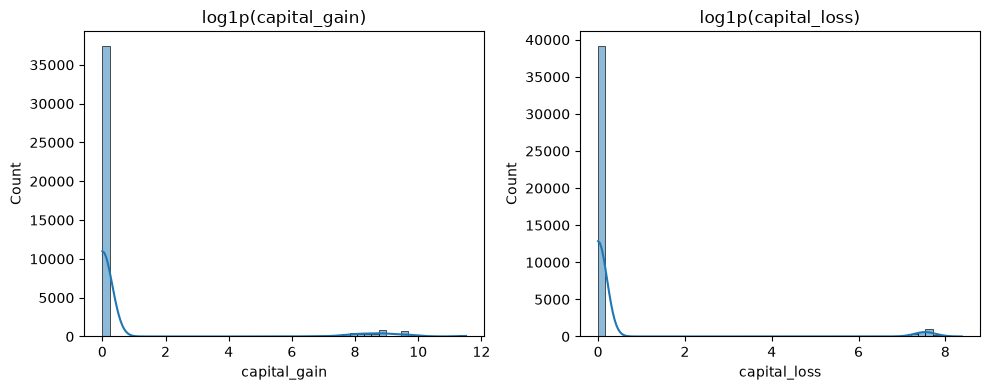

In [11]:
from sklearn.preprocessing import StandardScaler

skewed_cols = ["capital_gain", "capital_loss"]

z = pd.DataFrame(StandardScaler().fit_transform(df_adult[skewed_cols]), columns=skewed_cols)
logged = np.log1p(df_adult[skewed_cols])

print(pd.DataFrame({
    "skew (raw)": df_adult[skewed_cols].apply(skew),
    "skew (z-score)": z.apply(skew),
    "skew (log1p)": logged.apply(skew),
}).round(3))

fig, axes = plt.subplots(1, len(skewed_cols), figsize=(10, 4))
for ax, feature in zip(axes, skewed_cols):
    sns.histplot(logged[feature], bins=50, kde=True, ax=ax)
    ax.set_title(f"log1p({feature})")
plt.tight_layout()
plt.show()

**What we found:**
- Only `capital_gain` and `capital_loss` pass the |skew| > 1 rule.
- Z-score doesn't change skew at all as 11.014 → 11.014. It only shifts and rescales, so the shape stays the same.
- Log helps `capital_gain` a lot as 11.0 → 2.8 but barely helps `capital_loss` 4.2 → 3.9. Most values are exactly 0, and log1p(0) = 0, so the big pile at zero stays a pile.

**Conclusion:** We will use `log1p` on these two for logistic regression and the neural net. Tree models (XGBoost, random forest) don't need it, because splits only depend on the order of values.

### Correlation and Covariance

In [12]:
print(df_adult[num_adult].cov().round(2))

                    age  education_num  capital_gain  capital_loss  \
age              192.21           0.92       8185.75        286.96   
education_num      0.92           7.15       2769.42         96.55   
capital_gain    8185.75        2769.42   64432407.02    -128598.08   
capital_loss     286.96          96.55    -128598.08     188420.78   
hours_per_week     6.66           4.64       8624.01        299.56   

                hours_per_week  
age                       6.66  
education_num             4.64  
capital_gain           8624.01  
capital_loss            299.56  
hours_per_week          168.57  


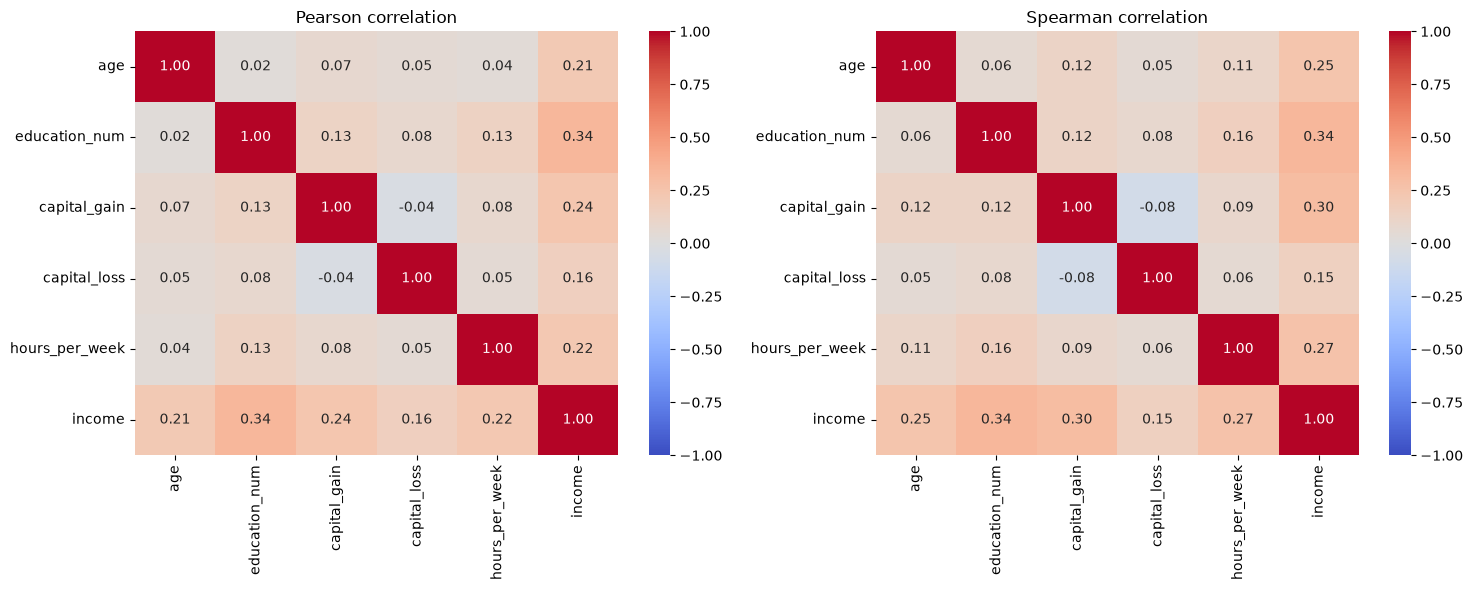

In [13]:
# Correlation is unitless, in [-1, 1]. Pearson = linear; Spearman = rank-based (monotonic, robust to outliers)
cols = num_adult + ["income"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(df_adult[cols].corr(method="pearson"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(df_adult[cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout()
plt.show()

In [14]:
# Correlation of each numeric feature with the output variable, sorted by strength
corr_with_y = pd.DataFrame({
    "pearson": df_adult[num_adult].corrwith(df_adult["income"]),
    "spearman": df_adult[num_adult].corrwith(df_adult["income"], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)
print(corr_with_y.round(3))

                pearson  spearman
education_num     0.338     0.338
capital_gain      0.241     0.302
hours_per_week    0.225     0.265
age               0.212     0.250
capital_loss      0.159     0.149


**What we found:**
- `education_num` is the strongest numeric predictor (0.34), then `capital_gain`, `hours_per_week` and `age` (around 0.21–0.24). `capital_loss` is weakest (0.16).
- All are weak to moderate showing that no single number decides income, which suggests models that combine features like trees, the neural net should do better than any one feature.
- Spearman is higher than Pearson for `capital_gain` as 0.30 is greater than 0.24 but the relationship is monotonic but not linear.
- The numeric features are barely correlated with each other, so none of them are redundant.

## Catagorical Feature Analysis

### Count and >50K rate for each category

In [15]:
for col in cat_adult:
    table = (df_adult.assign(**{col: df_adult[col].astype("object").fillna("<missing>")})
             .groupby(col)["income"].agg(count="size", rate_over_50K="mean")
             .sort_values("count", ascending=False))
    table["% of rows"] = 100 * table["count"] / len(df_adult)
    print(f"\n=== {col}: {len(table)} categories ===")
    print(table.head(10).round(3))


=== workclass: 9 categories ===
                  count  rate_over_50K  % of rows
workclass                                        
Private           27448          0.213     66.237
Self-emp-not-inc   3687          0.278      8.897
Local-gov          2960          0.292      7.143
<missing>          2393          0.105      5.775
State-gov          1914          0.266      4.619
Self-emp-inc       1628          0.549      3.929
Federal-gov        1378          0.385      3.325
Without-pay          21          0.095      0.051
Never-worked         10          0.000      0.024

=== marital_status: 7 categories ===
                       count  rate_over_50K  % of rows
marital_status                                        
Married-civ-spouse     18282          0.453     44.118
Never-married          13302          0.052     32.100
Divorced                6183          0.105     14.921
Separated               1511          0.065      3.646
Widowed                 1497          0.084      

### >50K rate for every categorical feature

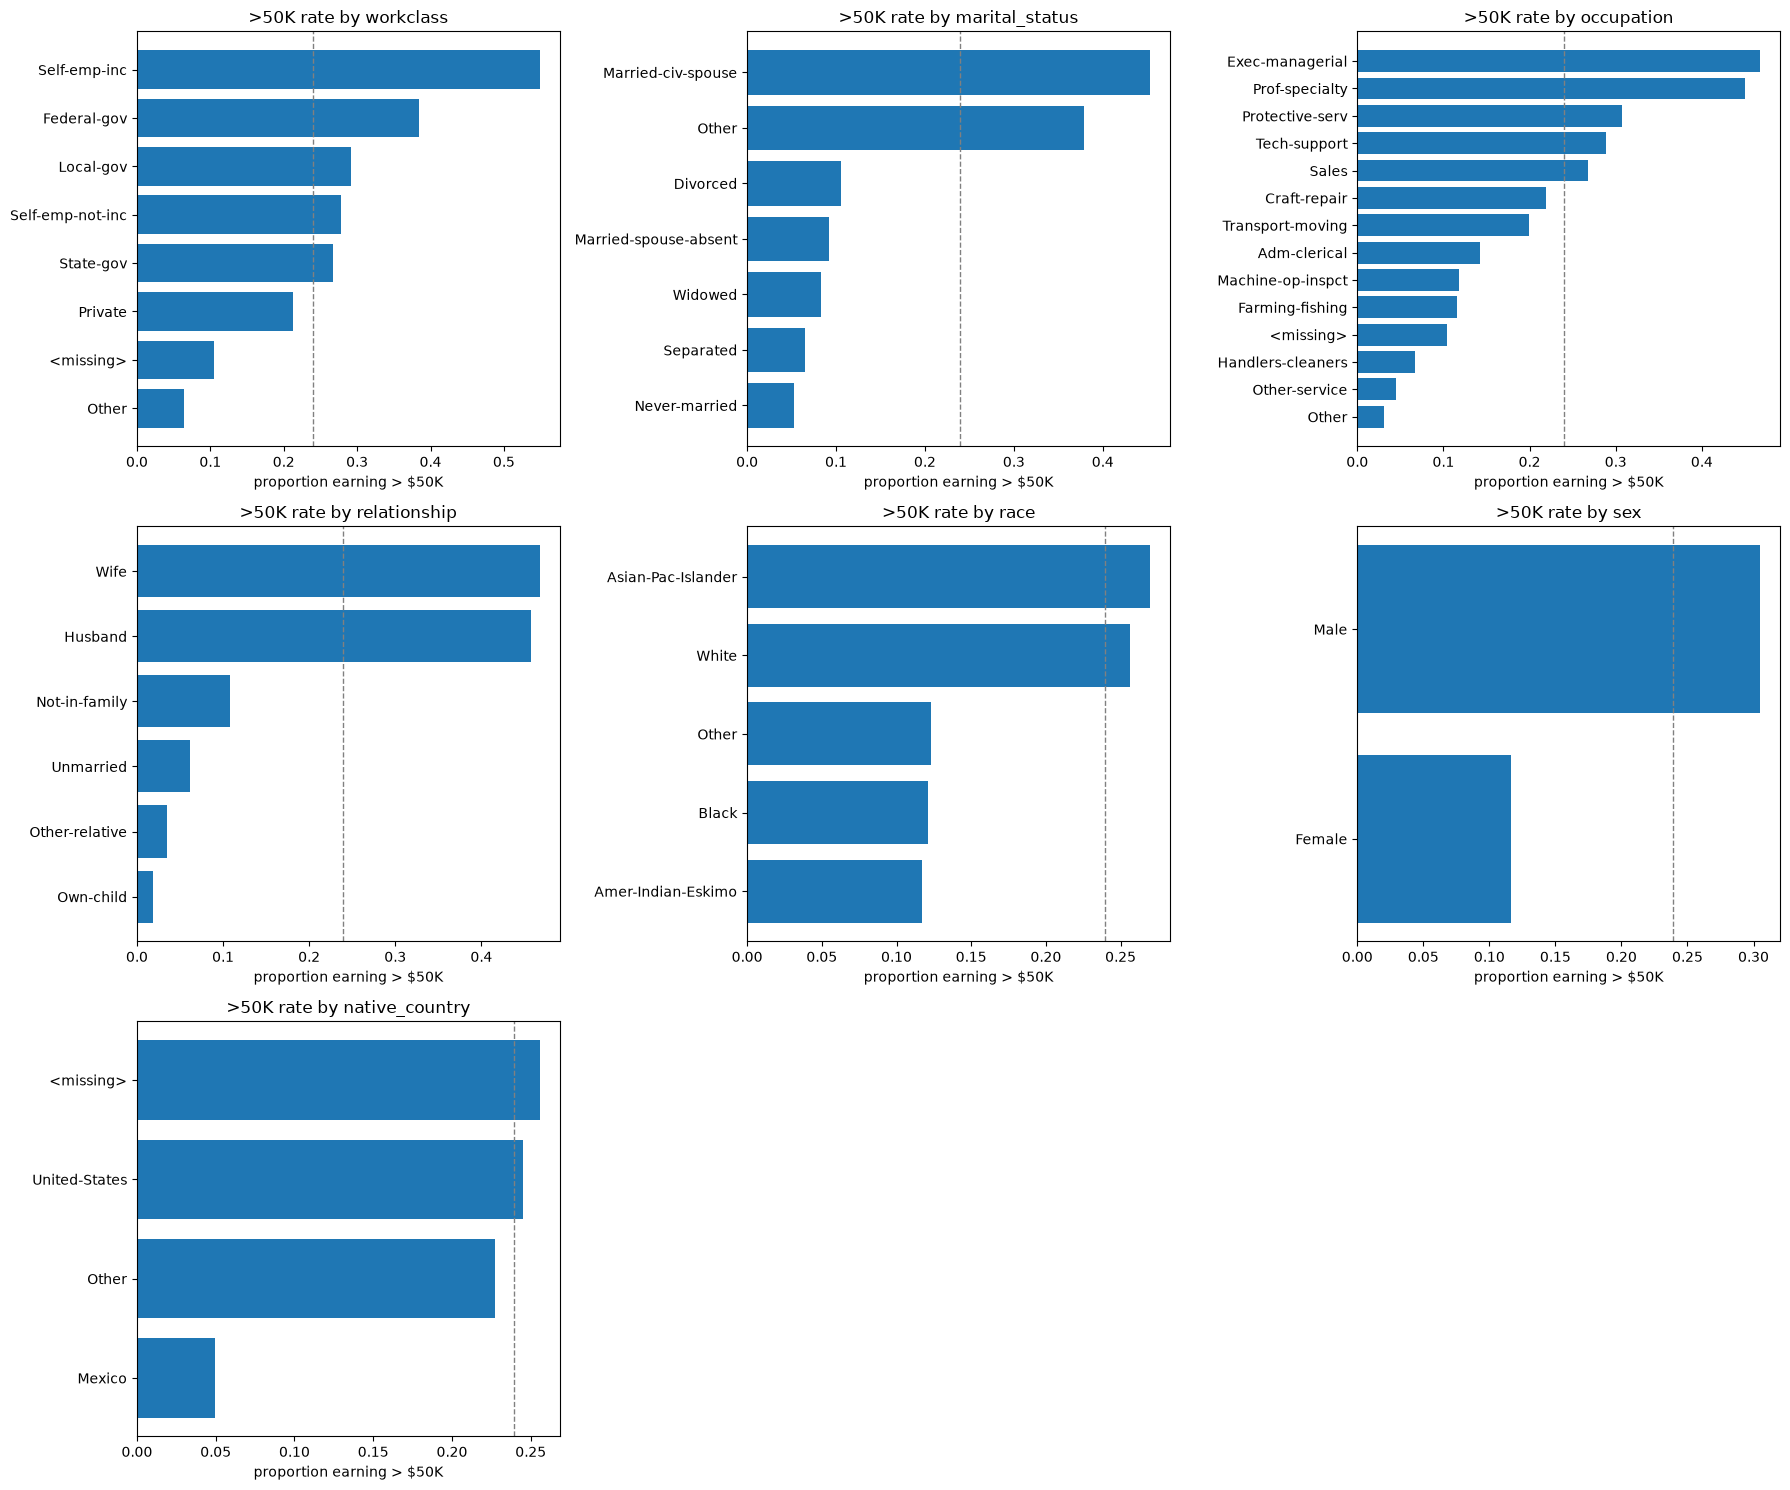

In [24]:
# Categories with < 1% of rows are grouped into "Other" so tiny groups don't clutter the plot!
ncols = 3
nrows = int(np.ceil(len(cat_adult) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))

for ax, col in zip(axes.ravel(), cat_adult):
    values = df_adult[col].astype("object").fillna("<missing>").astype(str)   # missing values get their own bar
    share = values.value_counts(normalize=True)
    rare = share[share < 0.01].index
    values = values.where(~values.isin(rare), "Other")

    rates = df_adult["income"].groupby(values).mean().sort_values()
    ax.barh(rates.index, rates.values)
    ax.axvline(df_adult["income"].mean(), color="gray", linestyle="--", linewidth=1)  # overall >50K rate
    ax.set_title(f">50K rate by {col}")
    ax.set_xlabel("proportion earning > $50K")

for ax in axes.ravel()[len(cat_adult):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

The dashed line is the overall >50K rate!

**What we found:**
- `marital_status` and `relationship` have the biggest gaps. married people earn >50K at 45%, never-married at 5%. Husbands at 46%, and wives (47%) are high. We see that "own child" is under 2%. These two features mostly say the same thing as being married implies you have a husband or wife, so they overlap.
- `occupation` show executives are at 47% and professionals are at 45% vs. "other service" at 4.5%.
- `workclass` shows self-employed incorporated is highest at 55%. The missing group is low at 10.5%.
- `sex` shows that men are 30.5% whereas women recieved 11.6%.
- `race` White individuals are att 25.7%, Asian-Pac-Islander are at 26.9%, vs. Black individuals are at 12.1%.
- `native_country` shows 88% are from the US, so most other countries fold into "Other".

`sex` and `race` show real gaps in the data. Since this is census data, those gaps reflect real world pay inequality. We report them but don't treat them as causes.

---
# Part 2: AI4I 2020 Predictive Maintenance

| Column | Meaning |
|---|---|
| `Type` | Product quality: L (low), M (medium), H (high) |
| `Air_temperature` | Air temperature (K) |
| `Process_temperature` | Process temperature (K) |
| `Rotational_speed` | Rotational speed (rpm) |
| `Torque` | Torque (Nm) |
| `Tool_wear` | Tool wear (min) |
| **`Machine failure`** | **Output variable:** 1 if the machine failed |

Dropped when loading: the ID columns (`UDI`, `Product ID`) and the five failure-mode flags (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`)

In [26]:
raw_ai4i = load_raw("ai4i")
X_ai4i, y_ai4i = load_dataset("ai4i")
df_ai4i = X_ai4i.assign(failure=y_ai4i)

num_ai4i, cat_ai4i = feature_types(X_ai4i)
print("Numeric features:    ", num_ai4i)
print("Categorical features:", cat_ai4i)
df_ai4i.head()

Numeric features:     ['Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear']
Categorical features: ['Type']


,Type,Air_temperature,Process_temperature,Rotational_speed,Torque,Tool_wear,failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## Check for missing or duplicated features, as well as possible signs of leakage

In [19]:
any_mode = raw_ai4i[AI4I_FAILURE_MODES].any(axis=1).astype(int)
print(pd.crosstab(any_mode, raw_ai4i["Machine_failure"],
                  rownames=["any failure mode"], colnames=["Machine failure"]))
print()
print(raw_ai4i[AI4I_FAILURE_MODES].sum().rename("count"))

Machine failure      0    1
any failure mode           
0                 9643    9
1                   18  330

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
Name: count, dtype: int64


In [20]:
print(f"Missing values: {X_ai4i.isna().sum().sum()}")
print(f"Duplicate rows: {df_ai4i.duplicated().sum()}")

Missing values: 0
Duplicate rows: 0


**What we found:**
- Leakage is confirmed. We see in 9,973 of 10,000 rows, "any failure mode" matches `Machine failure` exactly. The mismatches are only 9 failures with no mode, and 18 rows with a mode but no recorded failure. Thus, the five flag columns must stay dropped.
- We see no missing values and no duplicates so every missing value in our experiments will be one we inject, so we control exactly how much and what kind.

## How many machines fail and how many don't?

                 count  proportion
Machine failure                   
0                 9661       0.966
1                  339       0.034


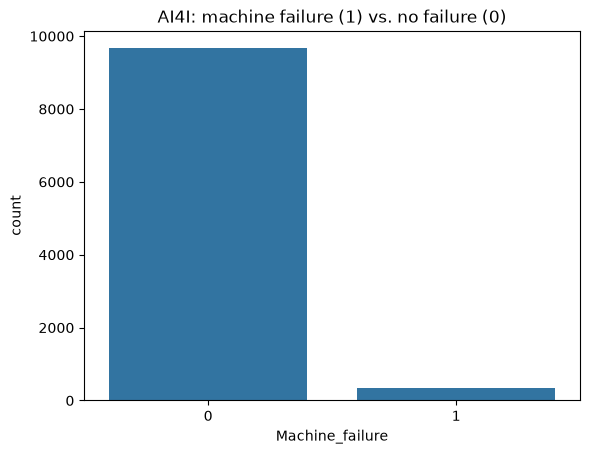

In [27]:
counts = y_ai4i.value_counts().sort_index()
print(pd.DataFrame({"count": counts, "proportion": (counts / counts.sum()).round(3)},
                   index=pd.Index([0, 1], name="Machine failure")))

sns.countplot(x=y_ai4i)
plt.title("AI4I: machine failure (1) vs. no failure (0)")
plt.show()

**What we found:**
- Only 3.4% of machines fail which is 339 of 10,000 machines, about 1 in 30.
- A model that always says "no failure" gets a 96.6% accuracy while catching zero failures. Accuracy is close to useless here, so F1 and PR-AUC are the main metrics for AI4I.
- With so few failures, flipping labels makes a large impact. Flipping just 5% of labels creates more fake failures of (around ~480) than there are real ones (approximately 339).

## Feature Plots and Basic Stats:

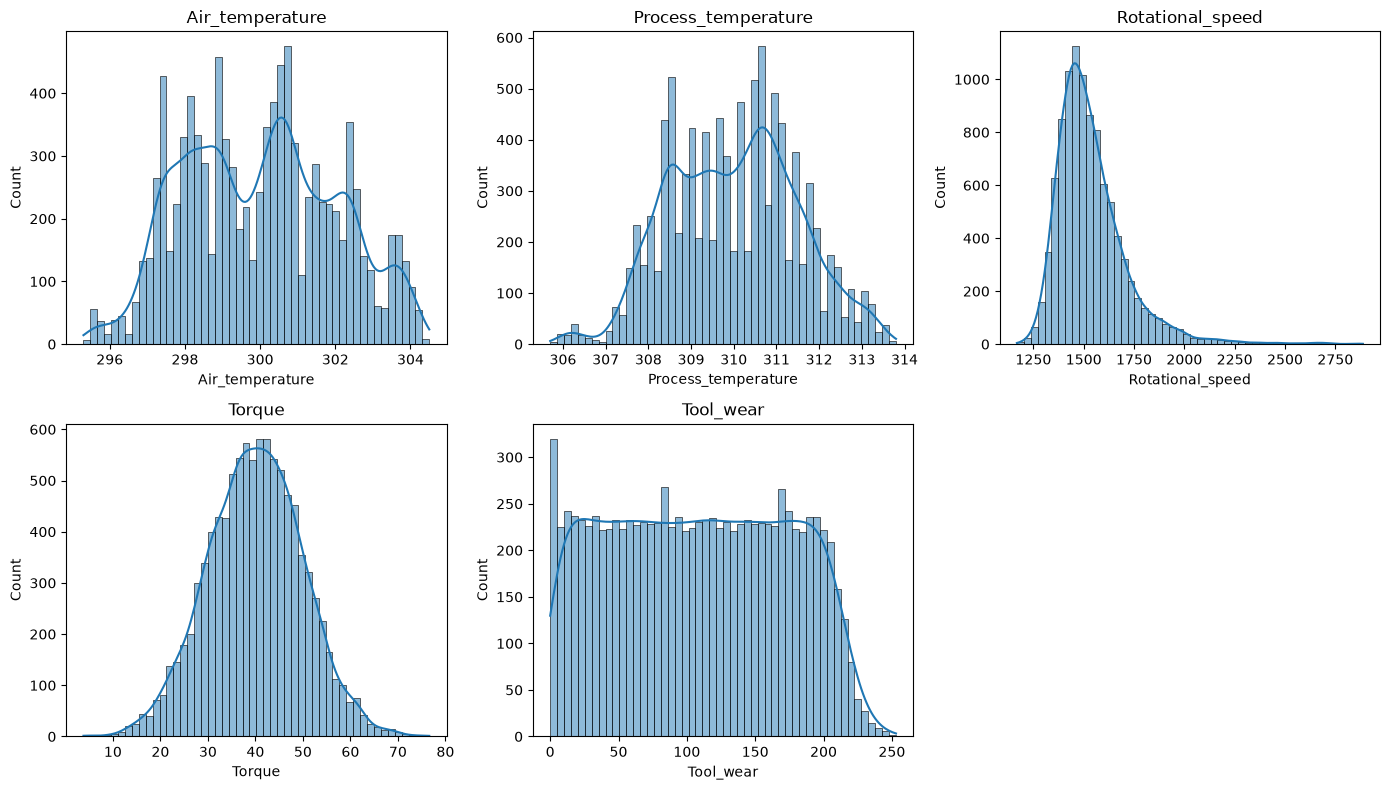

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.ravel(), num_ai4i):
    sns.histplot(df_ai4i[feature], bins=50, kde=True, ax=ax)
    ax.set_title(feature)
for ax in axes.ravel()[len(num_ai4i):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [29]:
stats = df_ai4i[num_ai4i].agg(["mean", "median", "std", "min", "max"]).T
stats["mean - median"] = stats["mean"] - stats["median"]
stats["pearson skew"] = 3 * stats["mean - median"] / stats["std"]
stats["sample skewness"] = df_ai4i[num_ai4i].apply(skew)
stats["(mean - min)/std"] = (stats["mean"] - stats["min"]) / stats["std"]
stats["(max - mean)/std"] = (stats["max"] - stats["mean"]) / stats["std"]
print(stats.round(3))

                         mean  median      std     min     max  mean - median  \
Air_temperature       300.005   300.1    2.000   295.3   304.5         -0.095   
Process_temperature   310.006   310.1    1.484   305.7   313.8         -0.094   
Rotational_speed     1538.776  1503.0  179.284  1168.0  2886.0         35.776   
Torque                 39.987    40.1    9.969     3.8    76.6         -0.113   
Tool_wear             107.951   108.0   63.654     0.0   253.0         -0.049   

                     pearson skew  sample skewness  (mean - min)/std  \
Air_temperature            -0.143            0.114             2.352   
Process_temperature        -0.191            0.015             2.902   
Rotational_speed            0.599            1.993             2.068   
Torque                     -0.034           -0.010             3.630   
Tool_wear                  -0.002            0.027             1.696   

                     (max - mean)/std  
Air_temperature                 2.247  


**What we found:**
- `Air_temperature`, `Process_temperature` and `Torque` are symmetric as the |skew| ≤ 0.11 and they appear close to bell-shaped.
- `Tool_wear` is symmetric (0.03) but flat. This shows tools are evenly spread from new to worn.
- `Rotational_speed` is the only skewed feature at 1.99, indicated it is right-skewed. The max is 7.5 std above the mean, while the min is only 2.1 std below.

### Differences between failed and working machines

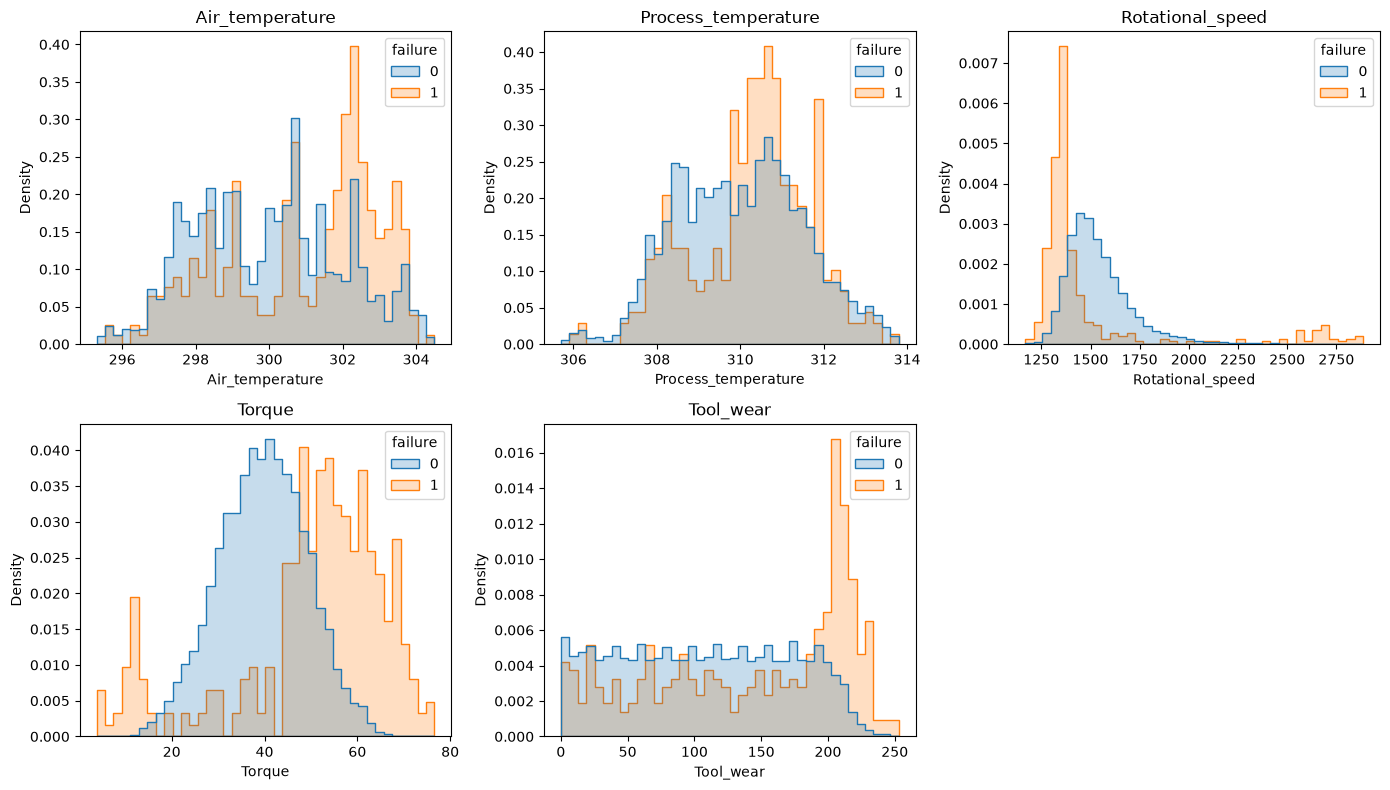

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.ravel(), num_ai4i):
    sns.histplot(data=df_ai4i, x=feature, hue="failure", bins=40,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(feature)
for ax in axes.ravel()[len(num_ai4i):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we found:**
- `Tool_wear` is flat for working machines, but failures spike sharply between 200 and 240 minutes. This shows tools start to fail once they pass about 200 minutes of wear.
- `Torque` failures mostly happen at high torque (50–75 Nm), above the working range of about 25–55 Nm. There is also a small group of failures at very low torque (5–15 Nm).
- `Rotational_speed` is the mirror image of torque. Most failures happen at low speed (about 1,250–1,400 rpm), with a small group at very high speed (2,300–2,900 rpm).
- `Air_temperature` failures shift toward the hot end, peaking around 302–303 K, while working machines are spread across 297–303 K.
- `Process_temperature` shows a similar but weaker shift, with failures clustered around 310–312 K.
- Failures sit at the edges of the distributions, and for speed and torque they sit at both ends. This explains why their correlations with failure are weak, and suggests tree models will do better than logistic regression here.

### Checking for Capped Values:

In [31]:
for col in num_ai4i:
    max_val = df_ai4i[col].max()
    n_at_max = (df_ai4i[col] == max_val).sum()
    print(f"{col:>20}: max = {max_val}, rows at max = {n_at_max} ({100 * n_at_max / len(df_ai4i):.2f}%)")

     Air_temperature: max = 304.5, rows at max = 1 (0.01%)
 Process_temperature: max = 313.8, rows at max = 2 (0.02%)
    Rotational_speed: max = 2886, rows at max = 1 (0.01%)
              Torque: max = 76.6, rows at max = 1 (0.01%)
           Tool_wear: max = 253, rows at max = 1 (0.01%)


**What we found:** every maximum is hit by only 1–2 rows, so essentially nothing is capped!

## Checking for Outliers:

In [32]:
Q1 = df_ai4i[num_ai4i].quantile(0.25)
Q2 = df_ai4i[num_ai4i].quantile(0.50)
Q3 = df_ai4i[num_ai4i].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

is_outlier = (df_ai4i[num_ai4i] < lower) | (df_ai4i[num_ai4i] > upper)

iqr_table = pd.DataFrame({"Q1": Q1, "Q2": Q2, "Q3": Q3, "IQR": IQR,
                          "lower bound": lower, "upper bound": upper,
                          "n outliers": is_outlier.sum(),
                          "% outliers": (100 * is_outlier.mean()).round(2)})
print(iqr_table.round(3))

                         Q1      Q2      Q3    IQR  lower bound  upper bound  \
Air_temperature       298.3   300.1   301.5    3.2       293.50       306.30   
Process_temperature   308.8   310.1   311.1    2.3       305.35       314.55   
Rotational_speed     1423.0  1503.0  1612.0  189.0      1139.50      1895.50   
Torque                 33.2    40.1    46.8   13.6        12.80        67.20   
Tool_wear              53.0   108.0   162.0  109.0      -110.50       325.50   

                     n outliers  % outliers  
Air_temperature               0        0.00  
Process_temperature           0        0.00  
Rotational_speed            418        4.18  
Torque                       69        0.69  
Tool_wear                     0        0.00  


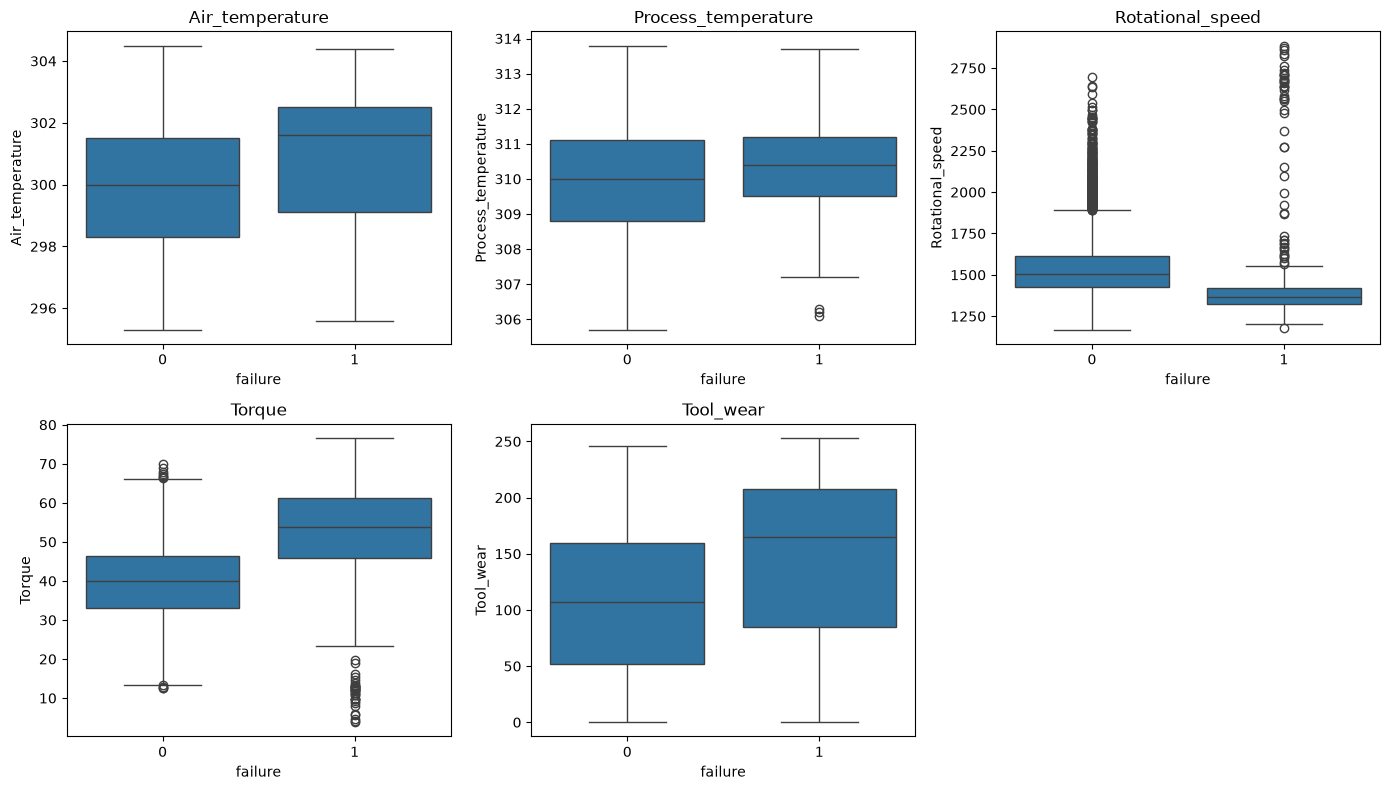

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feature in zip(axes.ravel(), num_ai4i):
    sns.boxplot(data=df_ai4i, x="failure", y=feature, ax=ax)
    ax.set_title(feature)
for ax in axes.ravel()[len(num_ai4i):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [34]:
any_outlier = is_outlier.any(axis=1)
print(f"Rows that are an outlier in at least one attribute: {any_outlier.sum():,} "
      f"({100 * any_outlier.mean():.2f}%)")
print(f"Failure rate in outlier rows: {y_ai4i[any_outlier].mean():.3f}, "
      f"in other rows: {y_ai4i[~any_outlier].mean():.3f}")

Rows that are an outlier in at least one attribute: 459 (4.59%)
Failure rate in outlier rows: 0.157, in other rows: 0.028


**What we found:**
- Only two features have outliers, which are `Rotational_speed` (418 rows, 4.2%) and `Torque` (69 rows, 0.7%). Together, this makes 459 rows (4.6%).
- Machines in those outlier rows fail at 15.7%, whereas 2.8% for the rest. This is over 5 times as often.

**Conclusion:** We decide to keep them as in equipment-failure data the outlier is actually the signal. For example, extreme speed or torque is when machines break. Removing outliers would remove the failures we're trying to predict.

## Transformations using Z-Score and Log

In [35]:
from sklearn.preprocessing import StandardScaler

z = pd.DataFrame(StandardScaler().fit_transform(df_ai4i[num_ai4i]), columns=num_ai4i)
logged = np.log1p(df_ai4i[num_ai4i])

print(pd.DataFrame({
    "skew (raw)": df_ai4i[num_ai4i].apply(skew),
    "skew (z-score)": z.apply(skew),
    "skew (log1p)": logged.apply(skew),
}).round(3))

                     skew (raw)  skew (z-score)  skew (log1p)
Air_temperature           0.114           0.114         0.103
Process_temperature       0.015           0.015         0.004
Rotational_speed          1.993           1.993         1.310
Torque                   -0.010          -0.010        -0.997
Tool_wear                 0.027           0.027        -1.810


**What we found:**
- Again, **Z-score never changes the skew**; it only rescales.
- Log helps `Rotational_speed` (1.99 → 1.31), the only skewed feature.
- But log **creates** skew in features that were fine: `Torque` goes 0 → −1.0 and `Tool_wear` goes 0 → −1.8.
  A log squeezes large values and stretches small ones, so it only helps right-skewed data.

**Decision:** log-transform at most `Rotational_speed`, and only for logistic regression and the neural net.
Leave the rest as they are.

## Correlation and Covariance Between Attributes:

In [36]:
print(df_ai4i[num_ai4i].cov().round(2))

                     Air_temperature  Process_temperature  Rotational_speed  \
Air_temperature                 4.00                 2.60              8.13   
Process_temperature             2.60                 2.20              5.13   
Rotational_speed                8.13                 5.13          32142.79   
Torque                         -0.27                -0.21          -1563.91   
Tool_wear                       1.76                 1.27              2.55   

                      Torque  Tool_wear  
Air_temperature        -0.27       1.76  
Process_temperature    -0.21       1.27  
Rotational_speed    -1563.91       2.55  
Torque                 99.38      -1.96  
Tool_wear              -1.96    4051.85  


### Correlation Heat Maps

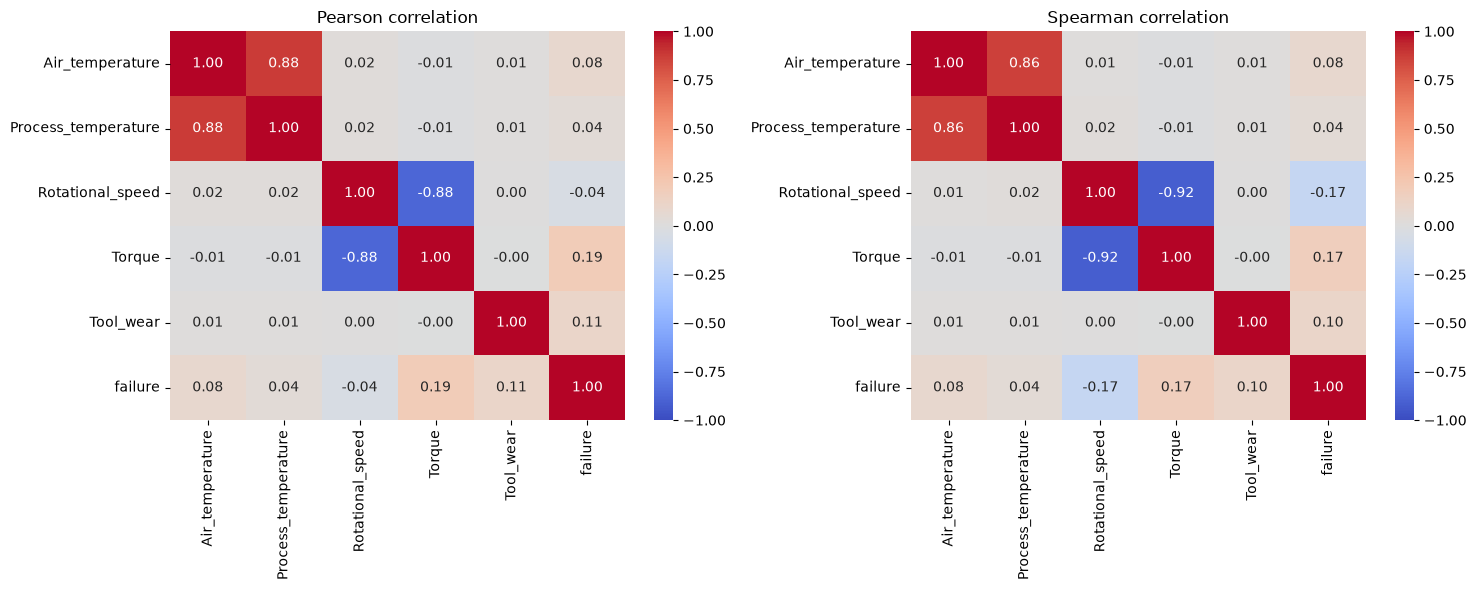

In [ ]:
cols = num_ai4i + ["failure"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(df_ai4i[cols].corr(method="pearson"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson correlation")
sns.heatmap(df_ai4i[cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman correlation")
plt.tight_layout()
plt.show()

Air_temperature   Process_temperature    0.876
Rotational_speed  Torque                 0.875
dtype: float64


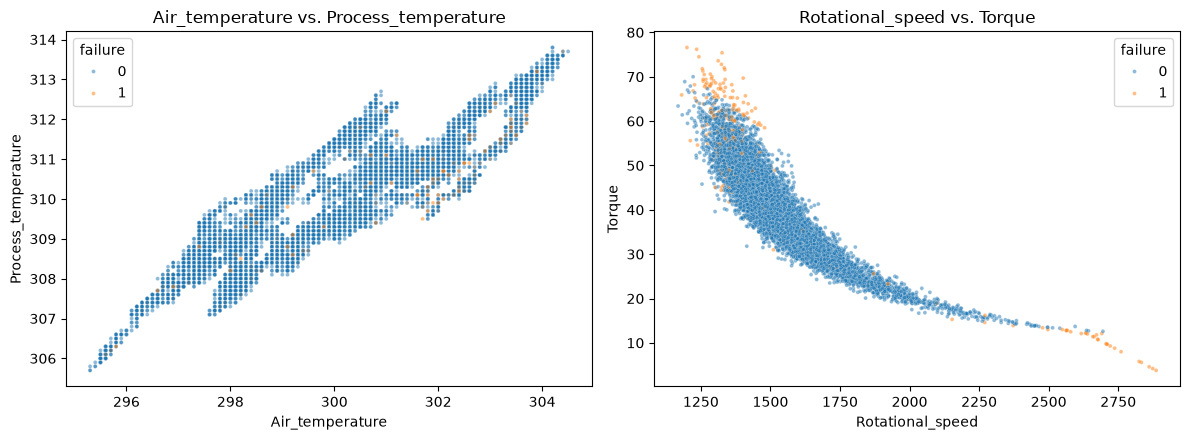

In [27]:
corr = df_ai4i[num_ai4i].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))   # upper triangle only, no repeats
             .stack().abs().sort_values(ascending=False))
top_pairs = pairs.index[:2].tolist()
print(pairs.head(2).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (x, y) in zip(axes, top_pairs):
    sns.scatterplot(data=df_ai4i, x=x, y=y, hue="failure", s=8, alpha=0.5, ax=ax)
    ax.set_title(f"{x} vs. {y}")
plt.tight_layout()
plt.show()

In [38]:
corr_with_y = pd.DataFrame({
    "pearson": df_ai4i[num_ai4i].corrwith(df_ai4i["failure"]),
    "spearman": df_ai4i[num_ai4i].corrwith(df_ai4i["failure"], method="spearman"),
}).sort_values("pearson", key=abs, ascending=False)
print(corr_with_y.round(3))

                     pearson  spearman
Torque                 0.191     0.169
Tool_wear              0.105     0.102
Air_temperature        0.083     0.083
Rotational_speed      -0.044    -0.167
Process_temperature    0.036     0.040


**What we found:**
- `Air_temperature` and `Process_temperature` are strongly correlated (r ≈ 0.88), since process temperature is roughly air temperature + 10 K.
- `Rotational_speed` and `Torque` are strongly negatively correlated (r ≈ −0.88). This shows that when speed goes up, torque goes down.
- All features are only weakly correlated with failure. `Torque` is the strongest at 0.19, followed by `Tool_wear` at 0.11.
- `Rotational_speed` has a Pearson correlation of −0.04 but a Spearman correlation of −0.17. This shows the relationship exists but is not a straight line, which fits failures happening at both extremes.
- Weak correlations combined with clear patterns at the edges suggest the data is nonlinear, so tree models should do better than logistic regression.
- Because of the two correlated pairs, corrupting only one feature in a pair may hurt less, since the model can partly recover it from its partner.

### Failures by Product Type

      count  failure_rate  % of rows
Type                                
H      1003         0.021      10.03
L      6000         0.039      60.00
M      2997         0.028      29.97


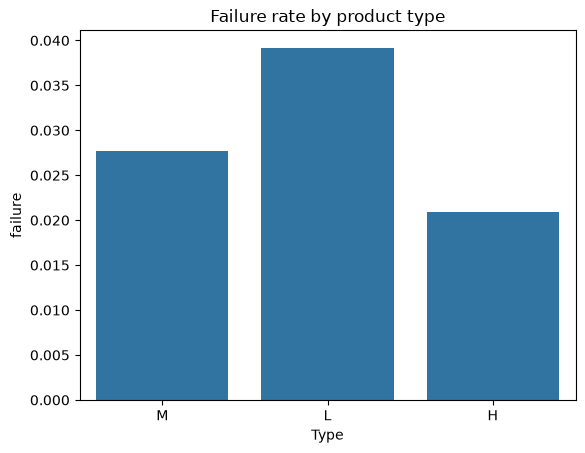

In [39]:
table = df_ai4i.groupby("Type", observed=True)["failure"].agg(count="size", failure_rate="mean")
table["% of rows"] = 100 * table["count"] / len(df_ai4i)
print(table.round(3))

sns.barplot(x=df_ai4i["Type"].astype(str), y=df_ai4i["failure"], errorbar=None)
plt.title("Failure rate by product type")
plt.show()

**What we found:**
- Lower-quality products fail more often. Type L has a failure rate of 3.9%, compared with 2.8% for M and 2.1% for H.
- Type L also makes up 60% of all products, so most failures come from type L (about 234 of the 339 failures, or 69%).
- The differences between types are small compared with the patterns in torque and tool wear, so `Type` is likely a weaker predictor than those features.

# Final Conclusions

**Adult Income:**
- The classes are imbalanced: 76% earn ≤50K and 24% earn >50K, so a model that always guesses ≤50K would already be 76% accurate.
- About 8% of rows have missing values in `workclass`, `occupation` or `native_country`. Missing `workclass` and `occupation` values are linked to lower income, so the missingness carries information.
- `capital_gain` and `capital_loss` are highly right-skewed, since almost everyone is at 0. A log transform helps `capital_gain` but barely changes `capital_loss`.
- `capital_gain` is capped at 99,999, and `hours_per_week` and `age` may also be capped.
- Outliers are real people, not errors, and they are more likely to earn >50K, so we keep them.
- Higher income goes with more education, older age, longer hours, and being married. `education_num`, `marital_status` and `relationship` show the biggest differences between the two groups.

**AI4I Predictive Maintenance:**
- The classes are severely imbalanced: only 3.4% of machines fail, so accuracy alone is misleading.
- The five failure-mode columns leak the answer, so they are dropped. There are no missing values or duplicates.
- Most features are symmetric. Only `Rotational_speed` is skewed, and no features are capped.
- Failures happen at the extremes. High tool wear (200+ minutes), high or very low torque, low or very high speed, and higher air temperature.
- Outliers are linked to failure, failing over 5 times as often as other rows, so we keep them.
- Air and process temperature move together, and speed and torque move in opposite directions.

**What this means for our experiments:**
- Use an 80/20 train/test split, and report F1 and PR-AUC along with accuracy, especially for AI4I.
- Keep outliers in both datasets.
- Let XGBoost handle missing values on its own, and give the other models "was missing" indicator columns so the comparison is fair.
- Log-transform skewed features only for logistic regression and the neural net. Tree models don't need it.
- Expect tree models (XGBoost, random forest) to do better than logistic regression, since many patterns are thresholds rather than straight lines.
- For single-feature corruption, start with the most important features: `education_num` for Adult, `Tool_wear` and `Torque` for AI4I.